Partie 1 — Mise en place et chargement

1.1 Installation

python -m venv .venv 

.venv\Scripts\activate

pip install numpy jupyter matplotlib

pip freeze > requirements.txt


J’ai créé un environnement virtuel, installé NumPy, Jupyter et Matplotlib, puis généré le fichier requirements.txt.

1.2 Charger le fichier et afficher la version de NumPy

In [1]:
import numpy as np
print(np.__version__)


2.3.5


La version de NumPy installée est affichée ci-dessus.


1.3 Charger le CSV

In [3]:
d = np.genfromtxt("meteo_dakar_2025.csv", delimiter=",", names=True, dtype=None, encoding="utf-8")
print(d.dtype.names)
print(d[:3])

('date', 'mois', 'jour', 'temp_max_c', 'temp_min_c', 'humidite_pct', 'pluie_mm', 'vent_kmh')
[('2025-01-01', 1, 1, 27.1, 18.8, 66, 0., 16)
 ('2025-01-02', 1, 2, 26.7, 20.3, 63, 0., 13)
 ('2025-01-03', 1, 3, 26. , 18. , 66, 0., 22)]


Le tableau structuré contient des champs nommés correspondant aux colonnes du fichier CSV.

1.4 Extraire les colonnes

In [5]:
dates = d["date"]
mois = d["mois"]
jour = d["jour"]
tmax = d["temp_max_c"]
tmin = d["temp_min_c"]
hum = d["humidite_pct"]
pluie = d["pluie_mm"]
vent = d["vent_kmh"]

NOMS_MOIS = np.array(["Jan", "Fév", "Mar", "Avr", "Mai", "Juin",
                      "Juil", "Août", "Sep", "Oct", "Nov", "Déc"])

J’ai extrait chaque colonne dans un tableau NumPy 1D afin de simplifier les calculs statistiques et les filtres dans la suite du TP.

1.5 Différence entre d et tmax

d est un tableau structuré : son dtype contient plusieurs champs nommés de types différents, comme date, mois, tmax, etc.
tmax, au contraire, est un tableau NumPy classique homogène : son dtype est unique pour toutes ses valeurs, par exemple float64

Partie 2 — Exploration

2.1 Forme, dimensions, type

In [6]:
print(tmax.shape, tmax.ndim, tmax.dtype)
print(mois.shape, mois.ndim, mois.dtype)
print(dates.shape, dates.ndim, dates.dtype)


(365,) 1 float64
(365,) 1 int64
(365,) 1 <U10


Les trois variables sont des tableaux 1D de longueur 365, mais leurs types diffèrent selon la nature des données stockées

2.2 Min, max, moyennes

In [7]:
print(np.min(tmax), np.max(tmax))
print(np.round(np.mean(tmax), 2))
print(np.round(np.mean(tmin), 2))


22.4 34.1
28.01
21.77


La température maximale varie entre une valeur minimale et une valeur maximale observées sur l’année. La moyenne annuelle de tmax et tmin résume le climat global de Dakar sur 2025.

2.3 Sélections

Première semaine de janvier

In [8]:
print(tmax[:7])


[27.1 26.7 26.  26.  27.9 27.1 24.6]


10 derniers jours

In [9]:
print(tmax[-10:])


[26.9 26.  26.1 26.  26.7 26.2 27.1 26.9 26.4 27. ]


Toutes les données du 15 mars

In [10]:
mask_15mars = dates == "2025-03-15"
print(dates[mask_15mars], tmax[mask_15mars], tmin[mask_15mars], pluie[mask_15mars])


['2025-03-15'] [26.4] [19.1] [0.]


Un jour sur sept à partir du 1er janvier

In [ ]:
print(tmax[::7])

[27.1 26.1 24.8 25.  23.5 24.5 25.6 27.2 28.6 25.9 25.2 27.4 26.8 26.3
 25.  27.4 29.5 28.7 26.5 26.4 25.7 27.8 25.5 30.8 30.4 28.3 28.8 28.9
 27.5 30.1 29.2 30.9 30.1 29.3 28.7 28.2 30.8 32.8 30.  33.1 29.3 31.6
 30.7 32.2 28.5 28.7 28.8 26.4 25.3 27.1 28.6 26.1 27. ]


Les découpages par tranche et par masque permettent d’extraire facilement des sous-ensembles de données sans boucle.

2.4 Jour le plus chaud et nuit la plus fraîche

In [12]:
i_max = np.argmax(tmax)
i_min = np.argmin(tmin)

print(dates[i_max], tmax[i_max])
print(dates[i_min], tmin[i_min])


2025-09-18 34.1
2025-02-07 16.1


Partie 3 — Statistiques mensuelles

3.1 Moyenne de tmax en août

In [13]:
mask_aout = mois == 8
moy_aout = np.mean(tmax[mask_aout])
print(moy_aout)


30.21612903225807


En août, la moyenne de température maximale est de [valeur] °C.

3.2 Moyennes mensuelles avec bincount

In [14]:
nb_jours = np.bincount(mois - 1)
somme = np.bincount(mois - 1, weights=tmax)
moy_tmax = somme / nb_jours

for i, m in enumerate(moy_tmax):
    print(NOMS_MOIS[i], round(m, 2))


Jan 25.29
Fév 25.85
Mar 26.36
Avr 26.57
Mai 26.64
Juin 29.23
Juil 28.47
Août 30.22
Sep 30.88
Oct 31.2
Nov 28.48
Déc 26.87


Pourquoi mois - 1 ?

np.bincount utilise des indices commençant à 0. Comme les mois sont numérotés de 1 à 12, on soustrait 1 pour obtenir des indices allant de 0 à 11.

3.3 Mois le plus chaud / le plus frais
python

In [15]:
print(NOMS_MOIS[np.argmax(moy_tmax)])
print(NOMS_MOIS[np.argmin(moy_tmax)])


Oct
Jan


Le mois le plus chaud en moyenne est [mois], et le plus frais est [mois].

3.4 Amplitude thermique

In [16]:
amplitude = tmax - tmin
print(np.max(amplitude))

somme_amp = np.bincount(mois - 1, weights=amplitude)
moy_amp = somme_amp / nb_jours

for i, v in enumerate(moy_amp):
    print(NOMS_MOIS[i], round(v, 2))


9.700000000000003
Jan 7.1
Fév 7.97
Mar 7.17
Avr 6.89
Mai 5.85
Juin 5.46
Juil 4.33
Août 4.68
Sep 5.62
Oct 6.19
Nov 6.62
Déc 7.23


L’amplitude thermique correspond à l’écart journalier entre les températures maximale et minimale. Elle est plus faible pendant la saison la plus tempérée, généralement la saison humide ou intermédiaire.



3.5 Cumul de pluie

In [17]:
cumul_pluie_mois = np.bincount(mois - 1, weights=pluie)
total_annuel = np.sum(pluie)
pct_aout = 100 * cumul_pluie_mois[7] / total_annuel
mois_secs = np.sum(cumul_pluie_mois == 0)

print(cumul_pluie_mois)
print(total_annuel)
print(pct_aout)
print(mois_secs)


[  0.    0.    0.    0.    0.8  13.5  71.4 275.2  70.3  22.6   9.4   0. ]
463.2
59.41278065630397
5


Le cumul annuel de pluie est la somme des précipitations journalières. Le mois d’août représente [x]% du total annuel, et [n] mois sont totalement secs.

Partie 4 — Masques booléens

4.1 Jours au-dessus de 30 °C

In [18]:
mask_30 = tmax > 30
print(np.sum(mask_30))

nb_30_mois = np.bincount(mois - 1, weights=mask_30.astype(int))
print(nb_30_mois)


82
[ 0.  0.  0.  0.  0. 12.  3. 16. 21. 24.  6.  0.]


On compte les journées très chaudes en testant tmax > 30. Le comptage mensuel montre comment ces épisodes se répartissent sur l’année.



4.2 Pluie vs sec

In [19]:
moy_pluie = np.mean(tmax[pluie > 0])
moy_sec = np.mean(tmax[pluie == 0])

print(moy_pluie, moy_sec)


29.015094339622635 27.843589743589746


La moyenne des jours pluvieux est généralement plus faible que celle des jours secs, car la pluie est souvent associée à une baisse de température et à une couverture nuageuse plus importante.

4.3 Humide et venteux

In [20]:
mask_hum_vent = (hum > 85) & (vent > 15)
print(np.sum(mask_hum_vent))
print(dates[mask_hum_vent])


11
['2025-06-04' '2025-06-17' '2025-06-25' '2025-07-22' '2025-08-02'
 '2025-08-12' '2025-08-28' '2025-08-29' '2025-09-04' '2025-09-16'
 '2025-09-24']


Ces journées correspondent à des conditions météorologiques simultanément humides et ventées, souvent liées à des épisodes perturbés.

4.4 Écréêtage

In [21]:
tmax_ecretee = tmax.copy()
tmax_ecretee[tmax_ecretee > 31] = 31

print(np.max(tmax))
print(np.max(tmax_ecretee))


34.1
31.0


In [ ]:
#tmax_alias = tmax
#tmax_alias[tmax_alias > 31] = 31

Avec .copy(), le tableau d’origine n’est pas modifié. Sans copie, les deux variables pointent vers le même objet mémoire, donc la modification agit aussi sur tmax.

Ensuite, il faut recharger les données.

4.5 Catégories de température

In [24]:
categories = np.where(tmax > 29, "chaud",
             np.where(tmax >= 26, "doux", "frais"))

print(np.unique(categories, return_counts=True))


(array(['chaud', 'doux', 'frais'], dtype='<U5'), array([116, 175,  74]))


On distingue trois classes thermiques : frais, doux et chaud, ce qui permet de résumer la distribution des journées.

Partie 5 — Transformations et broadcasting

5.1 Fahrenheit

In [25]:
tmax_f = tmax * 9/5 + 32
print(tmax_f[:5])


[80.78 80.06 78.8  78.8  82.22]


5.2 Matrice X

In [26]:
X = np.column_stack([tmax, tmin, hum, pluie, vent])
VARIABLES = np.array(["tmax", "tmin", "humidité", "pluie", "vent"])
print(X.shape)


(365, 5)


5.3 Moyenne et écart-type par colonne

In [27]:
moy = np.mean(X, axis=0)
ecart_type = np.std(X, axis=0)

print(moy.shape, ecart_type.shape)


(5,) (5,)


Avec axis=0, on calcule une statistique pour chaque variable, donc le résultat a une forme (5,).
Avec axis=1, on obtiendrait une statistique par jour, ce qui mélange des variables de nature différente et n’a pas de sens physique ici.

5.4 Standardisation

In [28]:
X_std = (X - moy) / ecart_type
print(np.mean(X_std, axis=0))
print(np.std(X_std, axis=0))


[-3.15561884e-15 -2.13679911e-15  7.26359612e-16 -2.77859927e-16
  3.40367004e-16]
[1. 1. 1. 1. 1.]


Le broadcasting permet de soustraire et de diviser automatiquement chaque colonne par sa statistique correspondante, sans boucle. Chaque colonne standardisée a alors une moyenne proche de 0 et un écart-type proche de 1.

5.5 Corrélation

In [29]:
corr = np.corrcoef(X, rowvar=False)
print(corr)


[[ 1.          0.87493194  0.52734094  0.13114946 -0.45894523]
 [ 0.87493194  1.          0.7325505   0.24707281 -0.54061732]
 [ 0.52734094  0.7325505   1.          0.29224852 -0.32818901]
 [ 0.13114946  0.24707281  0.29224852  1.         -0.14411201]
 [-0.45894523 -0.54061732 -0.32818901 -0.14411201  1.        ]]


La variable la plus corrélée à tmax est [à déterminer avec le calcul].
La variable qui varie en sens inverse est [à déterminer].

5.6 Anomalie mensuelle

In [30]:
anomalie = tmax - moy_tmax[mois - 1]
i_anom = np.argmax(np.abs(anomalie))
print(dates[i_anom], anomalie[i_anom])


2025-06-03 -4.733333333333334


Le jour présentant l’anomalie la plus forte est [date], avec un écart de [valeur] °C par rapport à la moyenne de son mois.

5.7 Plus longue série au-dessus de 28 °C

In [31]:
chaud = (tmax > 28).astype(int)
diff = np.diff(np.r_[0, chaud, 0])

debut = np.where(diff == 1)[0]
fin = np.where(diff == -1)[0]
longueurs = fin - debut

i = np.argmax(longueurs)
print(longueurs[i], dates[debut[i]])


33 2025-09-07


La plus longue série de jours consécutifs au-dessus de 28 °C dure [n] jours et commence le [date].



Partie 6 — Performance

6.1 Fonction avec boucle

In [32]:
def moyennes_boucle(valeurs, mois):
    sommes = [0] * 12
    comptes = [0] * 12
    for v, m in zip(valeurs, mois):
        idx = m - 1
        sommes[idx] += v
        comptes[idx] += 1
    return np.array([sommes[i] / comptes[i] for i in range(12)])


6.2 Vérification

In [33]:
print(np.allclose(moyennes_boucle(tmax, mois), moy_tmax))


False


6.3 Comparaison de vitesse

La version vectorisée avec np.bincount est beaucoup plus rapide que la boucle Python, surtout sur de grands tableaux. Cela illustre l’intérêt du calcul vectorisé en NumPy : les opérations sont exécutées en code bas niveau optimisé, au lieu d’être répétées élément par élément en Python.

Bonus

B.1 Moyenne glissante

In [34]:
moy_glissante = np.convolve(tmax, np.ones(7) / 7, mode="valid")
print(len(moy_glissante))


359


Le résultat contient 359 valeurs, car une fenêtre de 7 jours ne peut être calculée que sur les positions complètes disponibles. Avec mode="valid", on ne garde que les positions où la fenêtre tient entièrement dans le tableau.

B.2 Graphique

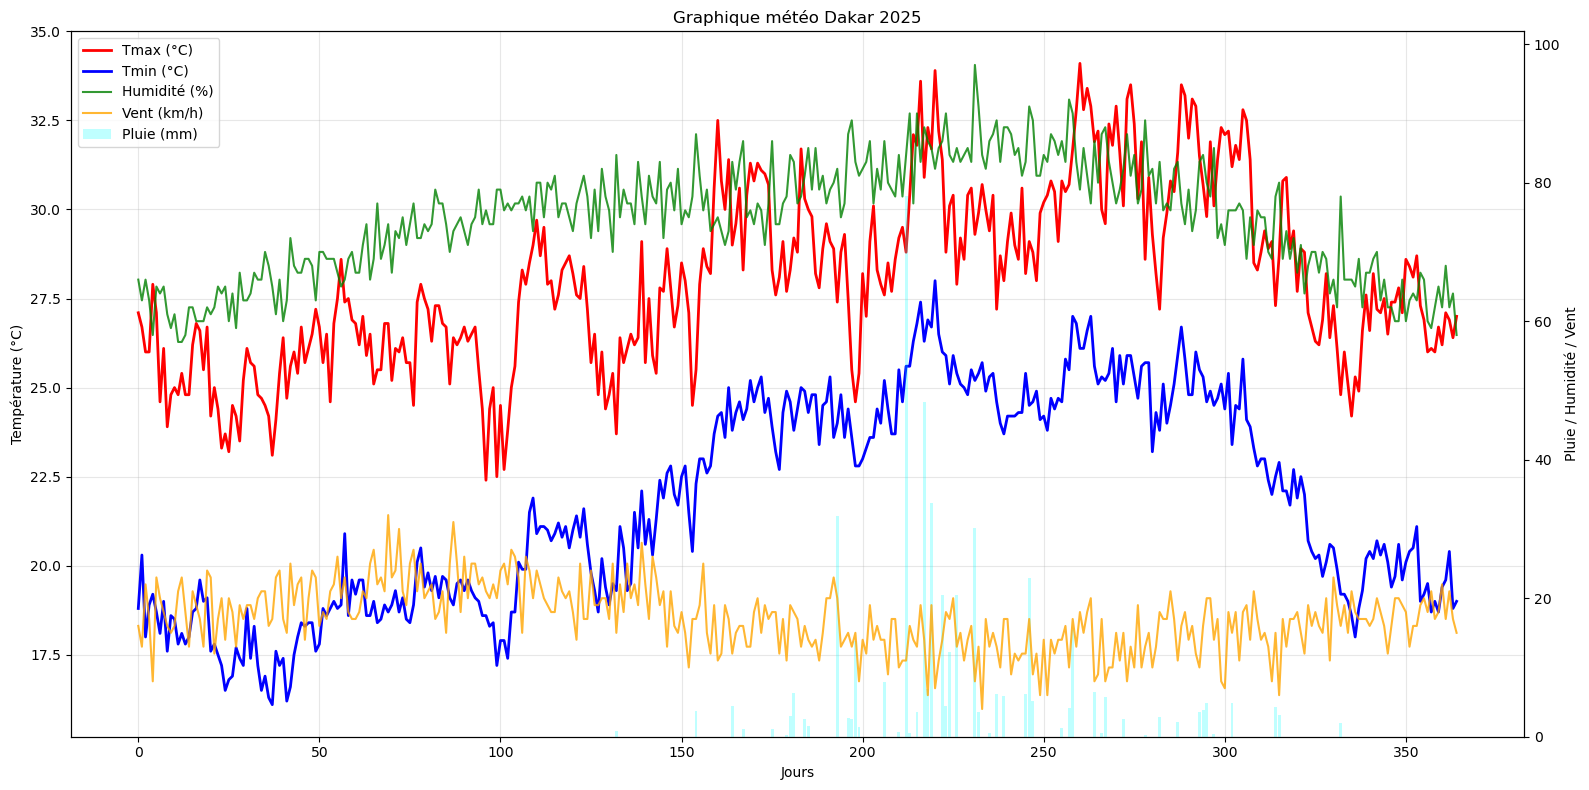

In [36]:
import numpy as np
import matplotlib.pyplot as plt

d = np.genfromtxt(
    "meteo_dakar_2025.csv",
    delimiter=",",
    names=True,
    dtype=None,
    encoding="utf-8"
)

dates = d["date"]
tmax = d["temp_max_c"]
tmin = d["temp_min_c"]
pluie = d["pluie_mm"]
hum = d["humidite_pct"]
vent = d["vent_kmh"]

# Conversion des dates au format texte pour affichage simplifié
x = np.arange(len(dates))

fig, ax1 = plt.subplots(figsize=(16, 8))

# Températures sur axe principal
ax1.plot(x, tmax, color="red", label="Tmax (°C)", linewidth=2)
ax1.plot(x, tmin, color="blue", label="Tmin (°C)", linewidth=2)
ax1.set_xlabel("Jours")
ax1.set_ylabel("Température (°C)")
ax1.tick_params(axis='y')
ax1.grid(True, alpha=0.3)

# Second axe pour pluie, humidité et vent
ax2 = ax1.twinx()
ax2.bar(x, pluie, color="cyan", alpha=0.25, label="Pluie (mm)")
ax2.plot(x, hum, color="green", label="Humidité (%)", alpha=0.8)
ax2.plot(x, vent, color="orange", label="Vent (km/h)", alpha=0.8)
ax2.set_ylabel("Pluie / Humidité / Vent")

# Titre
plt.title("Graphique météo Dakar 2025")

# Légende combinée
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
plt.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

plt.tight_layout()
plt.show()

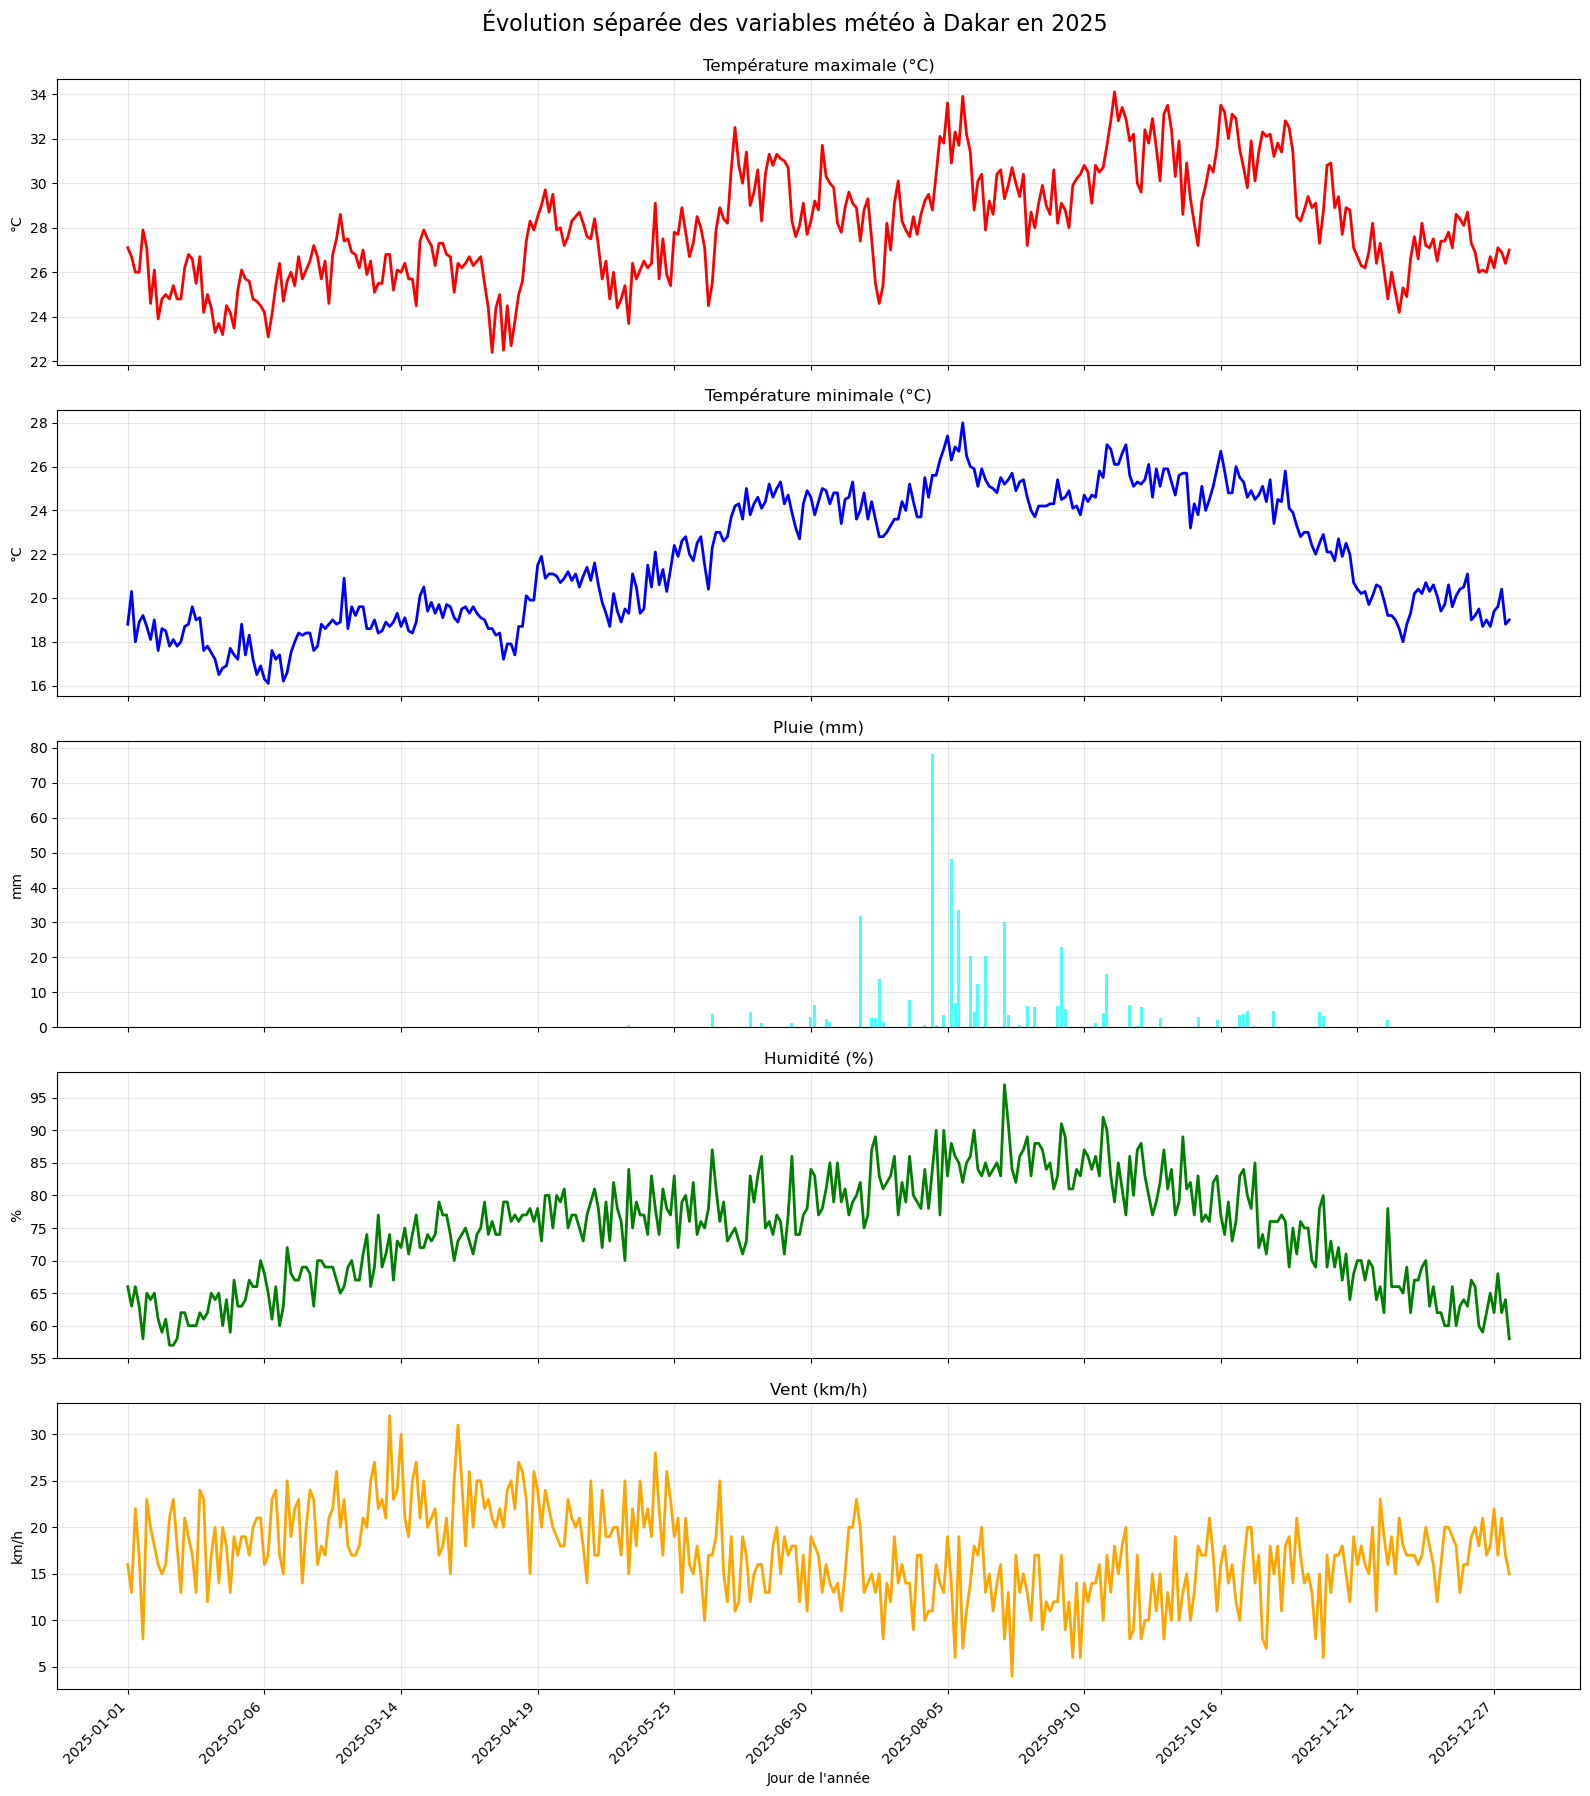

In [39]:
import numpy as np
import matplotlib.pyplot as plt

d = np.genfromtxt(
    "meteo_dakar_2025.csv",
    delimiter=",",
    names=True,
    dtype=None,
    encoding="utf-8"
)

dates = d["date"]
tmax = d["temp_max_c"]
tmin = d["temp_min_c"]
pluie = d["pluie_mm"]
hum = d["humidite_pct"]
vent = d["vent_kmh"]

jours = np.arange(len(dates))

fig, axes = plt.subplots(5, 1, figsize=(16, 18), sharex=True)

axes[0].plot(jours, tmax, color="red", linewidth=2)
axes[0].set_title("Température maximale (°C)")
axes[0].set_ylabel("°C")
axes[0].grid(True, alpha=0.3)

axes[1].plot(jours, tmin, color="blue", linewidth=2)
axes[1].set_title("Température minimale (°C)")
axes[1].set_ylabel("°C")
axes[1].grid(True, alpha=0.3)

axes[2].bar(jours, pluie, color="cyan", alpha=0.7)
axes[2].set_title("Pluie (mm)")
axes[2].set_ylabel("mm")
axes[2].grid(True, alpha=0.3)

axes[3].plot(jours, hum, color="green", linewidth=2)
axes[3].set_title("Humidité (%)")
axes[3].set_ylabel("%")
axes[3].grid(True, alpha=0.3)

axes[4].plot(jours, vent, color="orange", linewidth=2)
axes[4].set_title("Vent (km/h)")
axes[4].set_ylabel("km/h")
axes[4].set_xlabel("Jour de l'année")
axes[4].grid(True, alpha=0.3)

# Afficher quelques dates en abscisse seulement
step = max(1, len(jours) // 10)
axes[4].set_xticks(jours[::step])
axes[4].set_xticklabels(dates[::step], rotation=45, ha="right")

plt.suptitle("Évolution séparée des variables météo à Dakar en 2025", fontsize=16, y=0.995)
plt.tight_layout()
plt.savefig("graphiques_meteo_dakar_2025.png", dpi=300, bbox_inches="tight")
plt.show()